# Structured linear operators

`probjax.utils.linear_operator` represents a linear map by its *structure*
instead of a dense matrix. The structure decides how `solve`, `logdet`, and
`expm` are computed, and cheap structure is preserved under `+` and `@`.

The main operators are:

- `Diagonal` for elementwise scalings,
- `Dense` for a materialized matrix,
- `Function` for a matrix-free `matvec`,
- `Jacobian` for a matrix-free derivative at a point.

This notebook shows each one and when the structure pays off.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from probjax.utils.linear_operator import (
    Dense,
    Diagonal,
    Function,
    Jacobian,
    logdet,
    solve,
)

## Diagonal

A `Diagonal` operator is an elementwise scaling. Solving is a division, the
log-determinant is a sum of logs, and the matrix exponential stays diagonal.

In [2]:
diag = jnp.array([2.0, 3.0, 4.0])
x = jnp.array([1.0, 2.0, 3.0])
scaling = Diagonal(diag)

print("A @ x     :", scaling @ x)
print("A^-1 b    :", solve(scaling, jnp.array([2.0, 6.0, 12.0])))
print("logdet A  :", logdet(scaling))
print("expected  :", jnp.sum(jnp.log(diag)))
print("expm(0.5) :", scaling.expm(0.5) @ x)
print("structure preserved:", type(scaling.expm(0.5)).__name__)

A @ x     : [ 2.  6. 12.]
A^-1 b    : [1. 2. 3.]
logdet A  : 3.1780539
expected  : 3.1780539
expm(0.5) : [ 2.7182817  8.963378  22.167168 ]
structure preserved: Diagonal


## Dense

`Dense` wraps a matrix. With `psd=True`, `solve` uses a Cholesky factor and
`logdet` uses the triangular factor.

In [3]:
matrix = jnp.array([[2.0, 0.5], [0.5, 1.0]])
dense = Dense(matrix)
b = jnp.array([1.0, 2.0])

print("Dense solve:", solve(dense, b, psd=True))
print("direct solve:", jnp.linalg.solve(matrix, b))
print("Dense logdet:", logdet(dense, psd=True))

Dense solve: [4.2146848e-08 1.9999999e+00]
direct solve: [0. 2.]


Dense logdet: 0.5596158


## Composition simplifies structure

Composition keeps the cheapest representation: two diagonal operators stay
diagonal, while a diagonal composed with a dense matrix becomes dense.

In [4]:
v = jnp.array([1.0, 1.0])
diag_product = Diagonal(jnp.array([2.0, 3.0])) @ Diagonal(jnp.array([5.0, 0.5]))
print("diagonal @ diagonal:", type(diag_product).__name__, diag_product @ v)

composed = Diagonal(jnp.array([2.0, 3.0])) @ dense
print("composed @ v:", composed @ v)
print("diag * (A @ v):", jnp.array([2.0, 3.0]) * (matrix @ v))
print("composed type:", type(composed).__name__)

diagonal @ diagonal: Diagonal [10.   1.5]
composed @ v: [5.  4.5]
diag * (A @ v): [5.  4.5]
composed type: Dense


## A matrix-free operator

`Function` takes a linear `matvec` and never builds the matrix. This example is
a 1D Laplacian with a small shift (so it is positive definite), solved with
conjugate gradients. The dense matrix is shown only for comparison.

CG residual: 1.1751886631827801e-05


matches dense solve: True


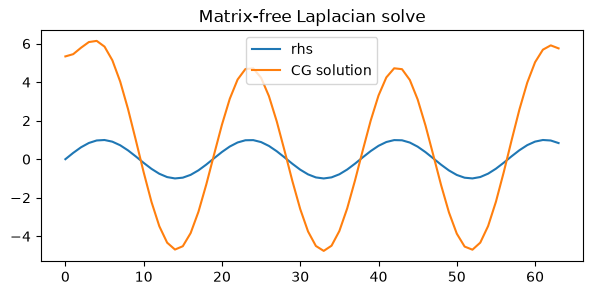

In [5]:
n = 64


def laplacian(x):
    return 2.0 * x - jnp.roll(x, 1) - jnp.roll(x, -1) + 0.1 * x


operator = Function(laplacian, in_shape=(n,), dtype=jnp.float32)
b = jnp.sin(jnp.arange(n) / 3.0)

solution = solve(operator, b, solver="cg", psd=True)
print("CG residual:", float(jnp.linalg.norm(laplacian(solution) - b)))

dense_laplacian = Dense(jax.jacfwd(laplacian)(jnp.zeros(n)))
dense_solution = solve(dense_laplacian, b, psd=True)
print("matches dense solve:", bool(jnp.allclose(solution, dense_solution, atol=1e-4)))

plt.figure(figsize=(7, 3))
plt.plot(b, label="rhs")
plt.plot(solution, label="CG solution")
plt.legend()
plt.title("Matrix-free Laplacian solve")
plt.show()

## Jacobians without a matrix

`Jacobian(fn, x)` applies the derivative of `fn` at `x` to a vector with one
JVP. It is the same linear map as `jax.jacfwd(fn)(x)`, but it never materializes
the matrix — useful when the input is large and only products are needed.

In [6]:
x0 = jnp.array([0.3, 0.7, 1.2])
direction = jnp.array([1.0, 0.0, 2.0])
jac = Jacobian(jnp.sin, x0)

print("Jacobian @ v:", jac @ direction)
print("jax.jvp     :", jax.jvp(jnp.sin, (x0,), (direction,))[1])
print("materialized shape:", jax.jacfwd(jnp.sin)(x0).shape)

Jacobian @ v: [0.9553365 0.        0.7247154]
jax.jvp     : [0.9553365 0.        0.7247154]


materialized shape: (3, 3)


## Takeaways

- Pick the operator by structure: `Diagonal` for elementwise maps, `Dense` for
  small materialized matrices, `Function`/`Jacobian` when a matrix would be too
  large.
- `solve`, `logdet`, and `expm` dispatch on that structure; composition and
  addition keep it where possible.
- `Function` and `Jacobian` are static pytree data: build them inside the
  traced function that uses them rather than passing them across `jit`/`scan`.